In [21]:
import os as os
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import matplotlib.pyplot as plt


In [ ]:
# Load the Hugging Face token from the local .env file (never committed to git)
from dotenv import load_dotenv
load_dotenv()

dictaBERT = "dicta-il/dictabert"

# Loading the tokenizer (dictionary)
tokenizer = AutoTokenizer.from_pretrained(dictaBERT)

# Loading the model with a regression head (num_labels=1 is the secret that produces a single number output)
model = AutoModelForSequenceClassification.from_pretrained(dictaBERT, num_labels=1)

In [23]:
# Load the dataset
# Make sure the CSV file is in the same directory or provide the full path
df = pd.read_csv('train.csv')

# Drop rows where any of the critical columns are missing
df = df.dropna(subset=['Title', 'Content', 'Content_score'])

# Concatenate the Title and Content with the [SEP] token
texts = df['Title'] + " [SEP] " + df['Content']

# Convert the scores to float (required for regression tasks)
labels = df['Content_score'].astype(float).tolist()


Token indices sequence length is longer than the specified maximum sequence length for this model (1010 > 512). Running this sequence through the model will result in indexing errors


The longest article has: 3764 tokens
The average article has: 579 tokens


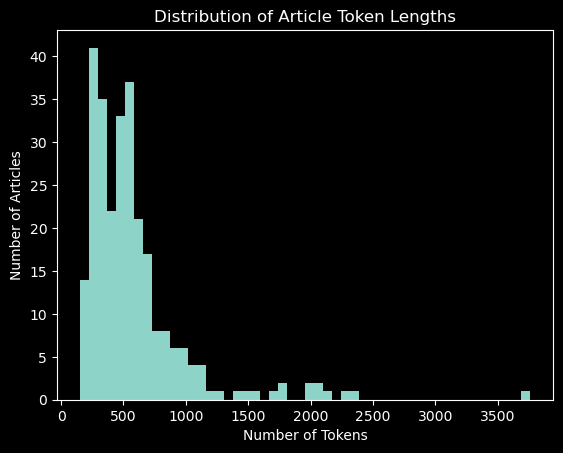

In [24]:

#Calculate the token length for every article
token_lengths = []

for text in texts:
    # Tokenize the text and count the number of tokens
    tokens = tokenizer.encode(text, add_special_tokens=True)
    token_lengths.append(len(tokens))

print(f"The longest article has: {max(token_lengths)} tokens")
print(f"The average article has: {sum(token_lengths) / len(token_lengths):.0f} tokens")

#Plot a histogram to see the distribution
plt.hist(token_lengths, bins=50)
plt.title("Distribution of Article Token Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Articles")
plt.show()

In [25]:
# Tokenize the concatenated texts
encoded_data = tokenizer(texts.tolist(), padding=True, truncation=True, max_length=512, return_tensors='pt')

print("Data processing and model loading completed successfully.")

Data processing and model loading completed successfully.


In [26]:
import torch
from sklearn.model_selection import train_test_split

#Split the data into Train (80%), Validation (10%), and Test (10%)

train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    texts.tolist(),
    labels,
    test_size=0.2,
    random_state=42
)

#Divide the 20% temp equally into Validation (10%) and Test (10%)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts,
    temp_labels,
    test_size=0.5,
    random_state=42
)

In [27]:
train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=512, return_tensors='pt')
val_encodings = tokenizer(val_texts, truncation=True, padding=True, max_length=512, return_tensors='pt')
test_encodings = tokenizer(test_texts, truncation=True, padding=True, max_length=512, return_tensors='pt')

In [28]:
class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        # Extract the tensors for a specific article
        item = {key: val[idx].clone().detach() for key, val in self.encodings.items()}
        # Add the label as a float tensor (required for regression)
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.float)
        return item

    def __len__(self):
        return len(self.labels)


In [29]:
# Instantiate the datasets for all three splits
train_dataset = NewsDataset(train_encodings, train_labels)
val_dataset = NewsDataset(val_encodings, val_labels)
test_dataset = NewsDataset(test_encodings, test_labels)

In [30]:
import torch

# Check if CUDA (NVIDIA GPU support) is available
if torch.cuda.is_available():
    # Get the number of available GPUs
    device_count = torch.cuda.device_count()
    # Get the name of the first GPU
    device_name = torch.cuda.get_device_name(0)
    print(f"Success! Found {device_count} GPU(s).")
    print(f"Using GPU: {device_name}")
else:
    print("Warning: GPU not found. PyTorch will use the CPU.")

In [31]:
import numpy as np
from sklearn.metrics import mean_squared_error
from transformers import Trainer, TrainingArguments

# ---------------------------------------------------------
# Step 5: Define Metrics and Configure the Trainer
# ---------------------------------------------------------

# Define the evaluation metric (Root Mean Squared Error)
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    # Squeeze the predictions array to ensure its shape matches the labels array
    predictions = predictions.squeeze()
    rmse = np.sqrt(mean_squared_error(labels, predictions))
    return {"rmse": rmse}

# Configure the training V1 parameters
training_args = TrainingArguments(
    output_dir='../results',          # Directory to save training V1 checkpoints
    num_train_epochs=4,              # Number of full passes through the training V1 data
    per_device_train_batch_size=8,   # Number of samples processed at once during training V1
    per_device_eval_batch_size=8,    # Number of samples processed at once during evaluation
    learning_rate=2e-5,              # Small learning rate to preserve pre-trained knowledge
    eval_strategy="epoch",           # Evaluate on the validation set at the end of each epoch
    save_strategy="epoch",           # Save a checkpoint at the end of each epoch
    load_best_model_at_end=True,     # Keep the model version with the lowest validation error
    metric_for_best_model="rmse",    # Track the RMSE metric
    greater_is_better=False          # Lower RMSE means fewer errors
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,        # Use the validation set to guide the training V1 process
    compute_metrics=compute_metrics
)

# ---------------------------------------------------------
# Step 6: Execute Training and Final Test Evaluation
# ---------------------------------------------------------

print("Starting the training V1 process...")
# This step might take some time depending on your hardware (CPU vs GPU)
trainer.train()

print("Training complete! Evaluating the final model on the unseen Test Set...")
# Evaluate the model on the test dataset to get an objective performance score
test_results = trainer.evaluate(test_dataset)
print(f"Final Test Set RMSE: {test_results['eval_rmse']:.4f}")

# ---------------------------------------------------------
# Step 7: Save the Fine-Tuned Model
# ---------------------------------------------------------

# Define the local directory path where the model will be saved
output_model_path = "../dictabert_morale_scorer"

# Save the trained model weights and the configuration
trainer.save_model(output_model_path)

# Save the tokenizer vocabulary so it matches the trained model
tokenizer.save_pretrained(output_model_path)

print(f"Success! Model and tokenizer saved to: {output_model_path}")

ImportError: Using the `Trainer` with `PyTorch` requires `accelerate>=1.1.0`: Please run `pip install transformers[torch]` or `pip install 'accelerate>=1.1.0'`

In [3]:
import requests
from bs4 import BeautifulSoup
import time # To add small delays so we don't overload the server

# ---------------------------------------------------------
# NEW FUNCTION: Scrape links from a specific category page
# ---------------------------------------------------------
def get_security_links(category_url, max_articles=5):
    """
    Scans a category page and extracts links only to relevant articles.
    """
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'
    }

    print(f"Scanning category for links: {category_url}")
    try:
        response = requests.get(category_url, headers=headers)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, 'html.parser')

        article_links = set() # Using a set to prevent duplicate links

        # Find all link tags (<a>) on the page
        for a_tag in soup.find_all('a', href=True):
            href = a_tag['href']

            # Smart filtering: In Ynet, actual news articles usually contain '/news/article/'
            if '/news/article/' in href:
                # Convert relative URLs to full absolute URLs
                if href.startswith('/'):
                    full_url = f"https://www.ynet.co.il{href}"
                else:
                    full_url = href

                article_links.add(full_url)

                # Stop when we have gathered enough article links
                if len(article_links) >= max_articles:
                    break

        return list(article_links)

    except Exception as e:
        print(f"Error extracting links: {e}")
        return []

# ---------------------------------------------------------
# Execution Block
# ---------------------------------------------------------
if __name__ == "__main__":
    # The URL for Ynet's "Military & Security" category
    security_category_url = "https://www.ynet.co.il/news/category/185"

    # 1. Get 5 links to security articles
    links_to_scrape = get_security_links(security_category_url, max_articles=5)

    print(f"\nFound {len(links_to_scrape)} security articles. Starting analysis...\n")
    print("-" * 40)

    # 2. Loop through the links and run our model on each one
    for url in links_to_scrape:
        print(f"Scraping: {url}")

        # Calling your existing functions (scrape_news_article and get_morale_score)
        # Note: Make sure those functions are defined above this block in your actual file!
        title, content = scrape_news_article(url)

        if title and content and len(content) > 50:
            score = get_morale_score(title, content)
            print(f"Title: {title}")
            print(f"Morale Score: {score}")

            # --- Here you would add your pandas to_csv code to save the log ---
            # pd.DataFrame(...).to_csv(...)

        else:
            print("Article is too short or scraping failed, skipping.")

        print("-" * 40)

        # Wait 2 seconds between articles to avoid getting blocked by the website
        time.sleep(2)

    print("\nFinished analyzing all security articles!")

Scanning category for links: https://www.ynet.co.il/news/category/185

Found 5 security articles. Starting analysis...

----------------------------------------
Scraping: https://www.ynet.co.il/news/article/sjbaefrnwl#autoplay


NameError: name 'scrape_news_article' is not defined